# 02 · The surrogate model

Explanation methods need a model they can query, and Pyomo is an optimiser, not a model of that kind. In this notebook I train a surrogate that imitates it: a regressor that maps the eight negotiation inputs to the minimum total debt Pyomo would return. The explanations in the following notebooks are computed on this surrogate, so it has to be accurate enough to be trusted.

In [1]:
from itertools import product

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xai_financing_surrogate.data import MODELS_DIR, load_dataset, split_dataset
from xai_financing_surrogate.plotting import BLUE, MUTED, ORANGE, apply_style

apply_style()
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(load_dataset())


def report(name, y_true, y_pred):
    """Regression metrics used throughout: MAE, RMSE and R²."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE={mae:7.2f}  RMSE={rmse:7.2f}  R²={r2:.3f}")

## 1. Train, validation and test split

37% of the samples need no debt at all (see notebook 01). Because that's such a big chunk of the data, the split is stratified on zero versus positive debt, so the three subsets keep the same proportion and their metrics are comparable. Train is used to fit the surrogate, validation to tune it, and test stays untouched until the final evaluation. The split lives in `data.py`, so every notebook gets exactly the same samples.

In [2]:
for name, target in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f"{name:<5} n={len(target):4d}  zero-debt share={(target == 0).mean():.1%}")

train n=4200  zero-debt share=37.3%
val   n= 900  zero-debt share=37.3%
test  n= 900  zero-debt share=37.3%


## 2. A linear baseline

The surrogate maps the eight negotiation inputs to a single number, the total debt over the 12 years, so this is a tabular regression problem rather than a time-series one. There is a time dimension inside Pyomo (debt, losses and the asset base carry over from one year to the next), but it stays inside the optimiser. Each row of the dataset is an independent combination of inputs with its resulting debt, and the order of the rows means nothing. Time-series models like ARIMA also wouldn't fit the year-by-year structure itself. They explain each value from the series' own past plus random noise, whereas here the trajectory is fully determined by the inputs, and since Pyomo optimises all 12 years at once, early decisions already take later years into account.

Before going for a black-box model, I fit a plain linear regression. It's the textbook transparent model, since its coefficients are the explanation, so it sets the bar: if a more complex surrogate can't clearly beat it, the extra opacity isn't worth it. I compare models with MAE, RMSE and R² on the validation set.

In [4]:
linear = LinearRegression().fit(X_train, y_train)
report('Linear regression (val)', y_val, linear.predict(X_val))

Linear regression (val)      MAE= 150.70  RMSE= 207.65  R²=0.641


The linear model captures the general trend (R² = 0.64) but its errors are large: an average miss of about 151 when the mean debt is around 248, so roughly 60% of a typical value. It also has no way to represent the floor at zero debt that more than a third of the samples sit on. A straight line can't go flat at zero and then start rising, so it ends up predicting debt where there is none and the other way round. A non-linear surrogate is clearly needed.

## 3. Gradient boosting

Gradient boosting builds a sequence of small decision trees, each one fitted to the errors left by the previous ones. Trees split the input space with thresholds, which is exactly what this problem needs: debt sits at a floor of zero over a big part of the space, and the tariff only matters once it goes above the cost of service. Boosting also picks up interactions between inputs without me specifying them. Last, tree models allow TreeSHAP, which computes exact Shapley values instead of a sampling approximation, so any mismatch I find later against Pyomo comes from the surrogate and not from the explainer.

In [5]:
gbr = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
report('Gradient boosting (val)', y_val, gbr.predict(X_val))

Gradient boosting (val)      MAE=  44.29  RMSE=  67.57  R²=0.962


With default settings, gradient boosting already cuts the validation MAE to under a third of the linear model's (44 against 151) and pushes R² from 0.64 to 0.962, which confirms the problem is strongly non-linear. An average error of around 44 is still about 18% of the mean debt though, so it's worth tuning the model before trusting its explanations.

## 4. Hyperparameter tuning

I tune the three settings that matter most for boosting: the number of trees, their depth and the learning rate. Each combination is fitted on the training set and scored on the validation set. The test set stays untouched, so the final score remains an honest estimate.

In [6]:
grid = {
    'n_estimators':  [200, 500, 1000],
    'max_depth':     [3, 4, 5],
    'learning_rate': [0.05, 0.1],
}

results = []
for n_est, depth, lr in product(*grid.values()):
    model = GradientBoostingRegressor(
        n_estimators=n_est, max_depth=depth, learning_rate=lr, random_state=42
    ).fit(X_train, y_train)
    val_pred = model.predict(X_val)
    results.append({'n_estimators': n_est, 'max_depth': depth, 'learning_rate': lr,
                    'val_MAE': mean_absolute_error(y_val, val_pred),
                    'val_RMSE': np.sqrt(mean_squared_error(y_val, val_pred))})

tuning = pd.DataFrame(results).sort_values('val_RMSE')
tuning.head(5).round(2)

,n_estimators,max_depth,learning_rate,val_MAE,val_RMSE
16,1000,5,0.05,24.18,40.68
17,1000,5,0.10,24.90,41.10
10,500,5,0.05,24.56,41.34
11,500,5,0.10,24.90,41.34
5,200,5,0.10,25.73,42.80


With the larger dataset the best grid combination reaches a validation MAE of 24.2 and RMSE of 40.7. All five top configurations use depth 5, the deepest value in the grid, so the optimum may lie beyond it. That makes sense with more data: deeper trees can capture more complex interactions without overfitting. The next search therefore moves the depth range up to 5–6 and adds row subsampling.

In [7]:
# One fit with 6000 trees per setting; staged_predict gives the validation error after each tree
for depth, lr in product([5, 6], [0.02, 0.05]):
    model = GradientBoostingRegressor(
        n_estimators=6000, max_depth=depth, learning_rate=lr, subsample=0.8, random_state=42
    ).fit(X_train, y_train)
    val_rmse = [np.sqrt(mean_squared_error(y_val, pred)) for pred in model.staged_predict(X_val)]
    best_n = int(np.argmin(val_rmse)) + 1
    print(f"depth={depth}  lr={lr}  RMSE at 3000 trees={val_rmse[2999]:.2f}  "
          f"best n_estimators={best_n:4d}  best RMSE={min(val_rmse):.2f}")

depth=5  lr=0.02  RMSE at 3000 trees=35.36  best n_estimators=6000  best RMSE=35.14
depth=5  lr=0.05  RMSE at 3000 trees=37.02  best n_estimators=5983  best RMSE=36.99
depth=6  lr=0.02  RMSE at 3000 trees=36.55  best n_estimators=5921  best RMSE=36.48
depth=6  lr=0.05  RMSE at 3000 trees=39.64  best n_estimators=5816  best RMSE=39.64


Adding row subsampling (each tree sees a random 80% of the training data, i.e. stochastic gradient boosting) and letting the model grow more trees brings the validation RMSE down to the 35–40 range. Depth 6 is worse than depth 5 at both learning rates, so depth 5 is an interior optimum rather than the edge of the search. To pick the number of trees I fitted each setting with 6000 trees and read the validation error after each one. The best values all land near 6000, but the curves are flat by then: for depth 5 and learning rate 0.02, going from 3000 to 6000 trees only lowers the RMSE from 35.36 to 35.14. I keep depth 5, learning rate 0.02 and 3000 trees: it is the most accurate configuration, and more trees would only slow down SHAP for no real gain.

## 5. Final surrogate and test performance

With the hyperparameters fixed, I refit both models on train and validation together, since validation has done its job and more data gives a better surrogate. Then I score them once on the untouched test set.

In [8]:
best_params = dict(n_estimators=3000, max_depth=5, learning_rate=0.02, subsample=0.8, random_state=42)

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

surrogate = GradientBoostingRegressor(**best_params).fit(X_trval, y_trval)
linear_final = LinearRegression().fit(X_trval, y_trval)

report('Linear regression (test)', y_test, linear_final.predict(X_test))
report('Gradient boosting (test)', y_test, surrogate.predict(X_test))

Linear regression (test)     MAE= 154.46  RMSE= 211.58  R²=0.623
Gradient boosting (test)     MAE=  19.08  RMSE=  31.52  R²=0.992


On the test set the gradient boosting surrogate reaches R² = 0.992 with an MAE of about 19, under 8% of the mean debt and eight times lower than the linear model. Its test RMSE (31.5) is even a bit lower than the validation one (35.4). That's expected, since the final model was refitted on train and validation together, so it learned from more data. It also confirms that tuning didn't overfit the validation set. The RMSE is still about 1.7 times the MAE though, which means most predictions are very accurate but a handful of samples carry larger errors.

## 6. Where does the surrogate go wrong?

The RMSE is about 1.7 times the MAE, so a few samples carry larger errors. The plot compares the surrogate's prediction with the true Pyomo debt for every test sample: on the dashed diagonal the prediction would be perfect, and the further a point sits from it, the bigger the error.

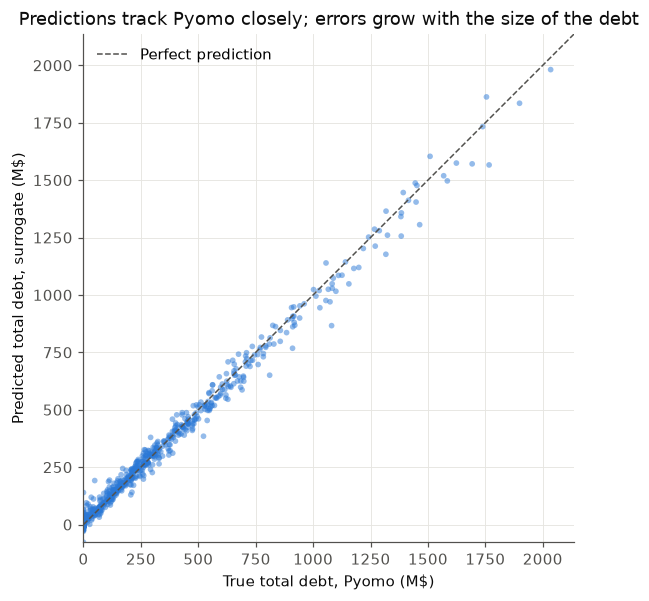

,samples,MAE
Zero debt,336,6.4
Positive debt,564,26.6
Top 10% debt,90,48.3


In [12]:
test_pred = surrogate.predict(X_test)
limit = max(y_test.max(), test_pred.max()) * 1.05

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred, s=14, color=BLUE, alpha=0.5, edgecolors='none')
ax.plot([0, limit], [0, limit], color=MUTED, linestyle='--', linewidth=1, label='Perfect prediction')
ax.set_xlim(0, limit)
ax.set_ylim(min(0, test_pred.min()), limit)
ax.set_aspect('equal')
ax.set_xlabel('True total debt, Pyomo (M$)')
ax.set_ylabel('Predicted total debt, surrogate (M$)')
ax.legend(frameon=False, loc='upper left')
ax.set_title('Predictions track Pyomo closely; errors grow with the size of the debt')
plt.show()

errors = (test_pred - y_test).abs()
regions = {'Zero debt': y_test == 0,
           'Positive debt': y_test > 0,
           'Top 10% debt': y_test >= y_test.quantile(0.9)}
pd.DataFrame({name: {'samples': mask.sum(), 'MAE': errors[mask].mean()}
              for name, mask in regions.items()}).T.round(1).astype({'samples': int})

The predictions follow Pyomo closely across the whole range, but the error isn't the same everywhere. On debt-free projects the surrogate is very accurate, with an average miss of only 6.4 M$, although it sometimes predicts a small positive debt where Pyomo says there is none. On indebted projects the average error rises to 26.6, and on the 10% largest debts it reaches 48.3: the points spread out as the debt grows, and above roughly 1400 M$ the surrogate tends to fall short. In relative terms these are still small errors on large debts, and they make sense, since the long right tail means there are few very large debts to learn from. For the explanations this means the surrogate is most trustworthy for low and moderate debts, and conclusions about the most extreme cases deserve some caution. Notebook 05 checks how much this actually affects the explanations.

## 7. Is the dataset large enough?

A first version of this analysis used 3000 samples, and its learning curve was still falling steeply at the full training size, so I regenerated the dataset with 6000. Here I check whether that was enough: I refit the final configuration on growing training sizes, from about the size of the old training set (2100) up to the full 4200, and track the validation error. If the curve flattens beyond 2100, doubling the data paid off and more samples wouldn't help much.

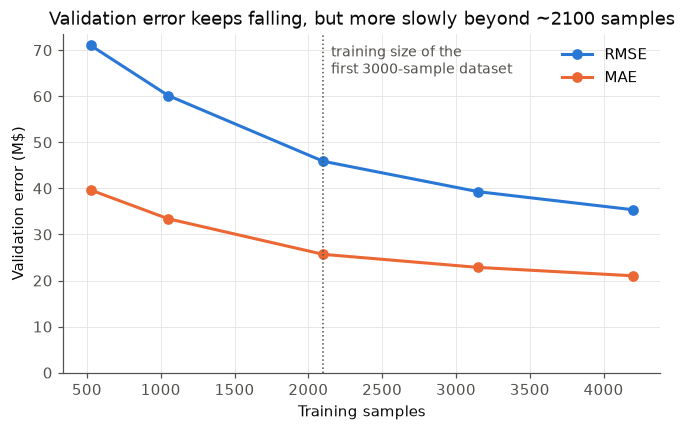

,n_train,MAE,RMSE
0,525,39.65,71.05
1,1050,33.41,60.16
2,2100,25.68,45.89
3,3150,22.85,39.28
4,4200,21.03,35.36


In [15]:
curve = []
for n in [525, 1050, 2100, 3150, 4200]:
    model = GradientBoostingRegressor(**best_params).fit(X_train.iloc[:n], y_train.iloc[:n])
    val_pred = model.predict(X_val)
    curve.append({'n_train': n, 'MAE': mean_absolute_error(y_val, val_pred),
                  'RMSE': np.sqrt(mean_squared_error(y_val, val_pred))})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve['n_train'], curve['RMSE'], marker='o', color=BLUE, linewidth=2, label='RMSE')
ax.plot(curve['n_train'], curve['MAE'], marker='o', color=ORANGE, linewidth=2, label='MAE')
ax.set_ylim(0, None)
ax.axvline(2100, color=MUTED, linestyle=':', linewidth=1)
ax.text(2100, ax.get_ylim()[1] * 0.97, '  training size of the\n  first 3000-sample dataset',
        color=MUTED, fontsize=9, va='top')
ax.set_xlabel('Training samples')
ax.set_ylabel('Validation error (M$)')
ax.legend(frameon=False)
ax.set_title('Validation error keeps falling, but more slowly beyond ~2100 samples')
plt.show()
curve.round(2)

Doubling the data clearly paid off: at the old training size (2100) the validation RMSE was about 46, and with the full 4200 it drops to about 35. Beyond 2100 the gains shrink, from 6.6 points in the next step to 3.9 in the last one, so the curve is flattening, although it isn't completely flat yet. Another doubling would probably shave off a few more points at the cost of roughly another hour of Pyomo solves. With a test R² of 0.992 I stop here. Whether the remaining error actually distorts the explanations is checked directly against Pyomo in notebook 05, which is a better basis for deciding than piling up more data blindly.S

## 8. Saving the surrogate

The following notebooks explain this exact model, so I save it once here instead of retraining it in each of them.

In [14]:
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(surrogate, MODELS_DIR / 'surrogate_gbr.joblib')

['C:\\Users\\agarr\\dev\\xai-financing-surrogate\\models\\surrogate_gbr.joblib']

## Summary

A linear model can't capture this problem: it explains only 64% of the variation in debt and has no way to represent the floor at zero. A tuned gradient boosting surrogate (depth 5, learning rate 0.02, 3000 trees with row subsampling) does much better, reaching R² = 0.992 on the untouched test set with an average error of about 19 M$, under 8% of the mean debt. It is very accurate on debt-free projects and less so on the largest debts, which are rare in the data, so conclusions about extreme cases need some caution. Doubling the dataset from 3000 to 6000 samples clearly helped, and the learning curve shows the gains are now slowing down. The surrogate is saved for the next notebooks, where it is explained with SHAP, PDP and LIME, and those explanations are then checked against Pyomo itself.